# Unit 3: Menelaah Data
**Kode unit:** J.62DMI00.005.1 · SKKNI No. 299 Tahun 2020 · Proyek: *Prediksi Arah Harian IHSG*

**Tujuan unit ini:** mengenal isi data: ukuran, tipe, pola, dan hubungan antarvariabel.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

## 1. Membaca data

In [2]:
df = pd.read_csv('../data/raw/market_data.csv', parse_dates=['Date'])
print('Jumlah baris :', len(df))
print('Jumlah kolom :', df.shape[1])
print('Periode      :', df['Date'].min().date(), 's.d.', df['Date'].max().date())
df.head()

Jumlah baris : 4365
Jumlah kolom : 6
Periode      : 2010-01-01 s.d. 2026-09-30


,Date,OIL,GOLD,SP500,IHSG,VIX
0,2010-01-01,NaN,NaN,NaN,NaN,NaN
1,2010-01-04,81.510002,1117.699951,1132.989990,2575.312988,20.040001
2,2010-01-05,81.769997,1118.099976,1136.520020,2605.175537,19.350000
3,2010-01-06,83.180000,1135.900024,1137.140015,2603.195557,19.160000
4,2010-01-07,82.660004,1133.099976,1141.689941,2586.794189,19.059999


| Kolom | Arti |
|---|---|
| Date | Tanggal (hari kerja) |
| IHSG | Indeks Harga Saham Gabungan |
| SP500 | Indeks saham Amerika |
| VIX | Indeks "ketakutan" pasar global |
| OIL, GOLD | Harga minyak dan emas (USD) |

**Sumber data:** Yahoo Finance (kode ^JKSE, ^GSPC, ^VIX, CL=F, GC=F), harga penutupan harian, diperbarui
sampai 30 September 2026. Pada hari libur suatu pasar, nilainya diisi dengan nilai hari sebelumnya.

## 2. Tipe data dan statistik ringkas

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4365 entries, 0 to 4364
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    4365 non-null   datetime64[ns]
 1   OIL     4364 non-null   float64       
 2   GOLD    4364 non-null   float64       
 3   SP500   4364 non-null   float64       
 4   IHSG    4364 non-null   float64       
 5   VIX     4364 non-null   float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 204.7 KB


In [4]:
df.describe().round(2)

,Date,OIL,GOLD,SP500,IHSG,VIX
count,4365,4364.00,4364.00,4364.00,4364.00,4364.00
mean,2018-05-14 23:48:07.422680320,72.08,1791.03,3135.73,5593.20,18.38
min,2010-01-01 00:00:00,-37.63,1050.80,1022.58,2475.48,9.14
25%,2014-03-10 00:00:00,55.70,1273.48,1848.38,4585.21,13.84
50%,2018-05-15 00:00:00,72.08,1561.25,2681.56,5783.32,16.70
75%,2022-07-20 00:00:00,88.91,1874.62,4224.32,6641.98,20.94
max,2026-09-30 00:00:00,123.70,5318.40,7798.99,9134.70,82.69
std,NaN,20.71,827.79,1706.70,1321.53,6.73


## 3. Grafik setiap variabel

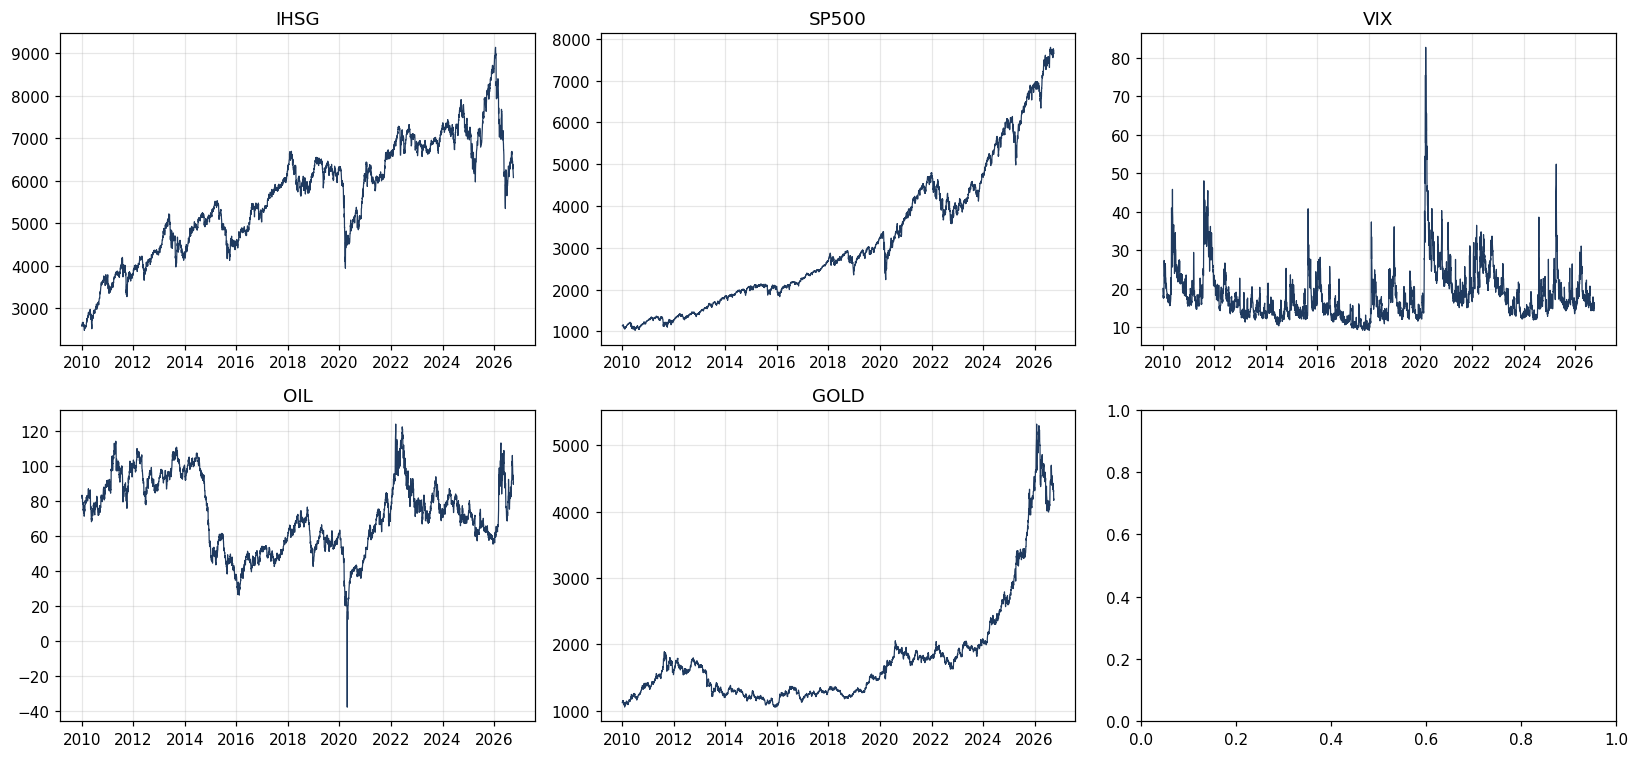

In [5]:
kolom = ['IHSG', 'SP500', 'VIX', 'OIL', 'GOLD']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, k in zip(axes.flat, kolom):
    ax.plot(df['Date'], df[k], linewidth=0.8, color='#1f3a5f')
    ax.set_title(k)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/03_grafik_variabel.png', dpi=150, bbox_inches='tight')
plt.show()

Terlihat beberapa hal yang perlu diperiksa di Unit 4: harga minyak (OIL) sempat **negatif** pada 2020, dan grafik
USD/IDR memiliki beberapa **lonjakan tajam ke bawah** yang tidak wajar.

## 4. Seberapa sering IHSG naik?

In [6]:
ihsg = df[['Date', 'IHSG']].dropna()
perubahan = ihsg['IHSG'].pct_change() * 100
perubahan = perubahan[perubahan != 0].dropna()   # abaikan hari libur BEI (nilai tidak berubah)
print(f'Hari IHSG naik  : {(perubahan > 0).mean():.1%}')
print(f'Hari IHSG turun : {(perubahan < 0).mean():.1%}')

Hari IHSG naik  : 54.0%
Hari IHSG turun : 46.0%


## 5. Variabel mana yang berhubungan dengan arah IHSG besok?
Kita hitung korelasi antara perubahan setiap variabel **hari ini** dengan perubahan IHSG **besok**. Agar adil, analisis
ini hanya memakai data 2010–2022 (data sesudahnya disimpan untuk pengujian). Korelasi Spearman dipakai karena tidak
mudah terpengaruh nilai ekstrem.

VIX     -0.236
IHSG     0.002
GOLD     0.086
OIL      0.137
SP500    0.289
Name: IHSG_besok, dtype: float64


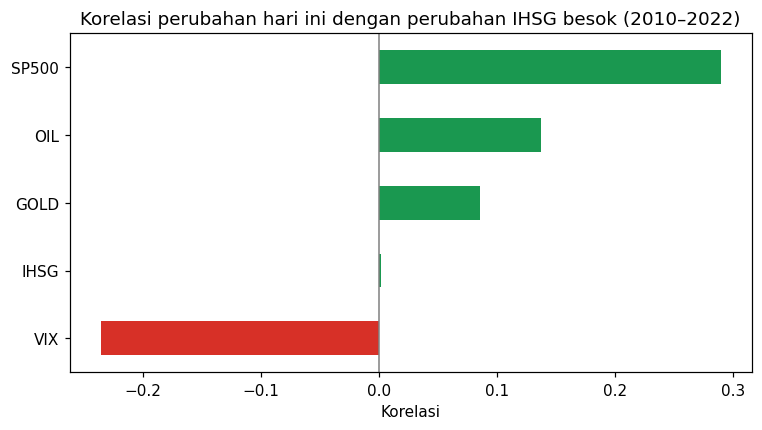

In [7]:
data = df[df['Date'] <= '2022-12-31'].dropna()
data = data[data['IHSG'].diff() != 0]            # hanya hari bursa BEI
chg = data[kolom].pct_change() * 100
chg['IHSG_besok'] = chg['IHSG'].shift(-1)
korelasi = chg.corr(method='spearman')['IHSG_besok'].drop('IHSG_besok').sort_values()
print(korelasi.round(3))

warna = ['#1a9850' if v > 0 else '#d73027' for v in korelasi]
korelasi.plot(kind='barh', color=warna, figsize=(8, 4))
plt.axvline(0, color='grey', linewidth=1)
plt.title('Korelasi perubahan hari ini dengan perubahan IHSG besok (2010–2022)')
plt.xlabel('Korelasi')
plt.savefig('../figures/03_korelasi_ihsg_besok.png', dpi=150, bbox_inches='tight')
plt.show()

## Kesimpulan
- Data berisi **4.365 hari kerja** (1 Jan 2010 – 30 Sep 2026) dengan 5 variabel pasar.
- IHSG naik pada sekitar **54%** hari bursa, jadi kelas Naik dan Turun cukup seimbang.
- **S&P 500** paling berhubungan dengan arah IHSG besok (korelasi +0,29): jika bursa Amerika naik semalam, IHSG
  cenderung naik keesokan harinya. **VIX** berhubungan terbalik (−0,24).
- Ada data yang janggal (harga minyak negatif) yang diperiksa di Unit 4.